# 02 · Spot quality control (QC)

**What this notebook does.** It measures, for every in-tissue spot, how much RNA was captured and whether the spot
passes the filter the paper describes, then shows where failing spots are on the tissue.

**Three QC measures (per spot):**
* `total_counts`: number of RNA molecules (UMIs) counted in the spot. Low = little material captured.
* `n_genes`: number of different genes with at least one count.
* `pct_mt`: percentage of counts from mitochondrial genes (symbols starting with `MT-`). High values are commonly
  read as damaged tissue.

**Filter used.** From the paper (Methods, p. 4401): *"Spots with more than 500 genes were retained, as well as spots
with less than 30% mitochondrial counts."* Implemented as `n_genes > 500` **and** `pct_mt < 30`
(the old notebook used `≥ 500`). Spots with 0 counts have no defined `pct_mt` and fail.

The filter is **recorded, not applied destructively**: every spot keeps its data with a `qc_pass` flag; later
notebooks select `qc_pass == True`.

| | |
|---|---|
| **Inputs** | processed `.h5ad` files (notebook 01), `manifests/tissue_sections.csv`, `manifests/spots.csv.gz` |
| **Outputs** | QC columns in the `.h5ad` files and in `manifests/spots.csv.gz`; `manifests/qc_summary.csv`; `figures/02_qc/*.png` |

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio        # all data processing
import spacemel_plots as splot   # all drawing

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "02_qc"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures ->:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures ->: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\02_qc
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


## 2.1 · Compute QC metrics for every section

Metrics are computed from the raw counts (`layers["counts"]`) and written back into each section's `.h5ad`.

In [2]:
usable = sio.usable_sections(P)
ts = pd.read_csv(MAN / "tissue_sections.csv")
in_paper = dict(zip(ts.section_id, ts.in_paper_S1C))
adatas = {}
for g, s in usable:
    a = sio.read_processed(P, g, s)
    sio.add_qc_metrics(a)
    a.write_h5ad(sio.processed_path(P, g, s), compression="gzip")
    adatas[(g, s)] = a
print("sections:", len(adatas))

sections: 18


## 2.2 · Gene panels and mitochondrial genes

GSE298774 contains two probe panels. The number of `MT-` genes differs per panel, which affects `pct_mt`.

In [3]:
panels = pd.DataFrame([{"gsm": g, "section_id": s, "n_genes_panel": a.n_vars, "n_MT_genes": a.uns["n_mt_genes"]}
                       for (g, s), a in adatas.items()])
panels.groupby(["n_genes_panel", "n_MT_genes"])["section_id"].apply(lambda x: ", ".join(x)).to_frame("sections")

,,sections
n_genes_panel,n_MT_genes,
18085,11,"A21, A16, A23"
37082,13,"A17, A7, A22, A24, A34, B1, B38ex, B4, B13, B8, B14, B15, B38_2, D20, D3"


## 2.3 · QC summary per section

`pct_pass_*` = percentage of the section's in-tissue spots passing each rule. `in_paper_S1C` = section is among the
18 individuals the paper analysed.

In [4]:
rows = []
for (g, s), a in adatas.items():
    o = a.obs
    rows.append({"gsm": g, "section_id": s, "patient_id": o.patient_id.iloc[0],
                 "in_paper_S1C": in_paper.get(s), "n_spots": a.n_obs,
                 "median_counts": float(o.total_counts.median()), "median_genes": float(o.n_genes.median()),
                 "median_pct_mt": float(o.pct_mt.median()),
                 "n_zero_count_spots": int((o.total_counts == 0).sum()),
                 "pct_pass_genes": round(100 * o.qc_genes_ok.mean(), 1),
                 "pct_pass_mt": round(100 * o.qc_mt_ok.mean(), 1),
                 "pct_pass_both": round(100 * o.qc_pass.mean(), 1),
                 "n_pass": int(o.qc_pass.sum())})
qc_summary = pd.DataFrame(rows).sort_values("median_counts", ascending=False)
qc_summary.to_csv(MAN / "qc_summary.csv", index=False)
qc_summary

,gsm,section_id,patient_id,in_paper_S1C,n_spots,median_counts,median_genes,median_pct_mt,n_zero_count_spots,pct_pass_genes,pct_pass_mt,pct_pass_both,n_pass
16,GSM9022973,D20,D20,True,1089,21899.0,5637.0,5.946685,0,97.0,100.0,97.0,1056
8,GSM9022969,B1,B1,True,3952,19684.5,5075.0,3.561734,0,99.5,100.0,99.5,3931
9,GSM9022969,B38ex,B38,False,1861,11309.0,3469.0,3.644133,0,99.7,100.0,99.7,1855
6,GSM9022967,A24,A24,True,6165,11291.0,3400.0,4.351362,0,98.3,100.0,98.3,6059
2,GSM9022965,A21,A21,True,2260,5914.5,2129.0,4.678807,0,85.6,100.0,85.6,1934
5,GSM9022967,A22,A22,True,4326,4010.0,1546.0,5.747922,1,94.3,100.0,94.3,4081
17,GSM9022973,D3,D3,True,1501,3846.0,1622.0,2.980132,0,80.5,100.0,80.5,1208
10,GSM9022970,B4,B4,True,6415,3374.0,1199.0,2.774108,0,84.5,100.0,84.5,5419
4,GSM9022966,A23,A23,True,2782,2811.5,1099.0,4.875793,0,77.0,100.0,77.0,2143
3,GSM9022966,A16,A16,True,5195,1246.0,554.0,4.069767,0,53.3,100.0,53.3,2768


## 2.4 · Distributions per section

Each violin shows all in-tissue spots of one section (sorted by median counts). Red dashed lines are the
thresholds. Counts and genes are shown on a log10 scale.

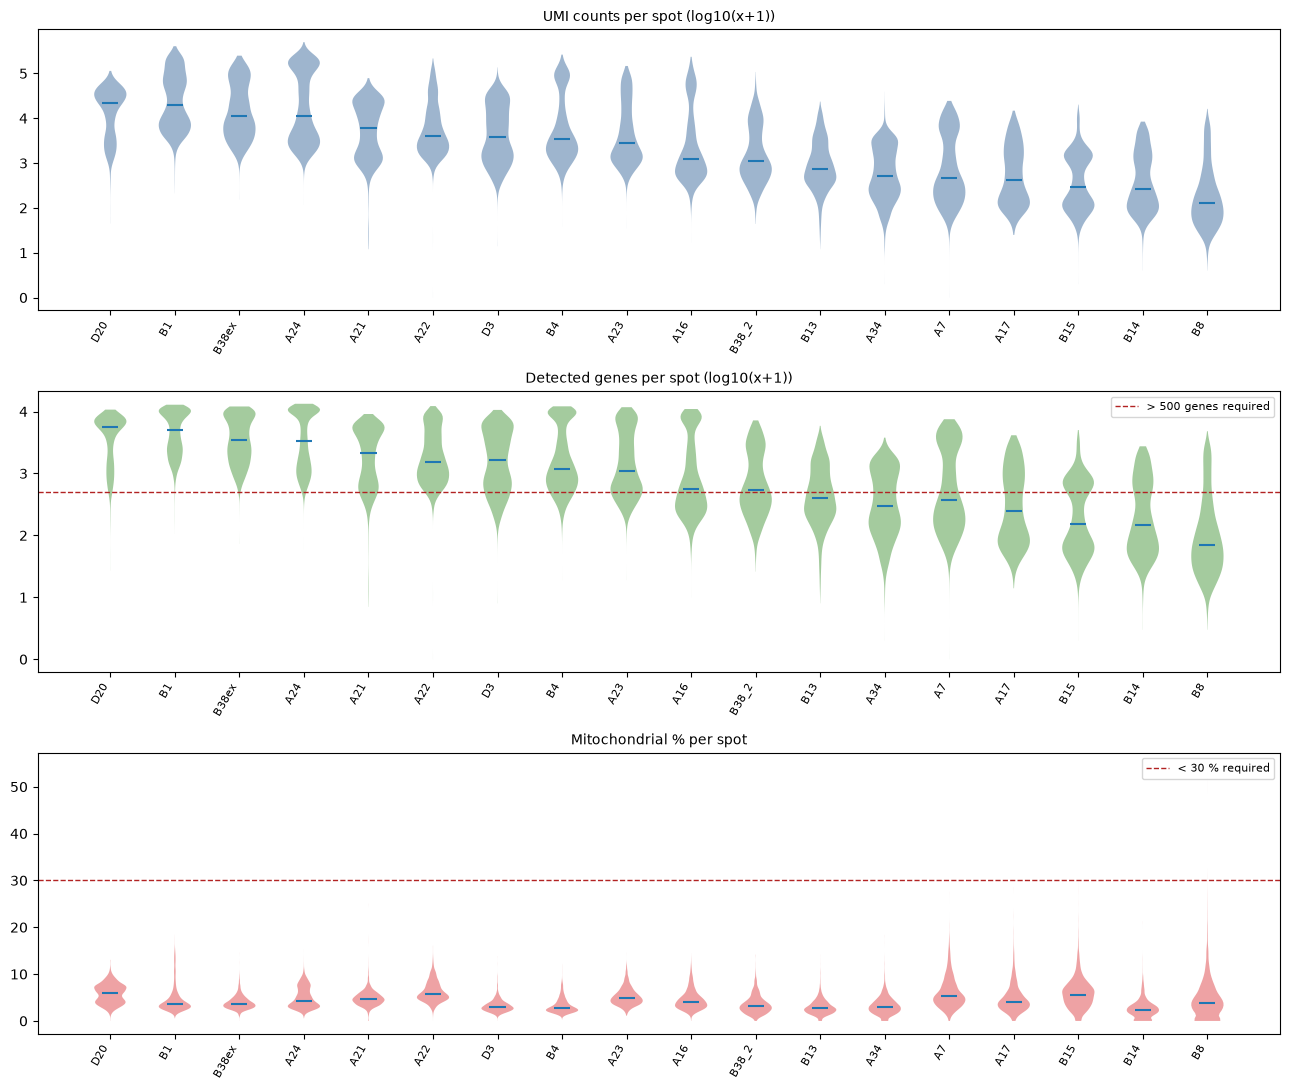

In [5]:
order = list(qc_summary.section_id)
by = {s: adatas[(g, s)].obs for g, s in adatas}
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
splot.violin_by_group(axes[0], {s: by[s].total_counts for s in order}, "UMI counts per spot (log10(x+1))", log=True)
splot.violin_by_group(axes[1], {s: by[s].n_genes for s in order}, "Detected genes per spot (log10(x+1))", log=True,
                      threshold=sio.QC_MIN_GENES_EXCLUSIVE, thr_label="> 500 genes required", color="#59a14f")
splot.violin_by_group(axes[2], {s: by[s].pct_mt for s in order}, "Mitochondrial % per spot",
                      threshold=sio.QC_MAX_PCT_MT_EXCLUSIVE, thr_label="< 30 % required", color="#e15759")
fig.tight_layout()
splot.savefig(fig, FIG / "qc_violins.png")
plt.show()

## 2.5 · Where are the failing spots?

For each section: spots coloured by `n_genes` (log10) on the hires H&E, at true size; spots failing QC are outlined
in red. This shows whether failures are scattered or concentrated in a tissue region.

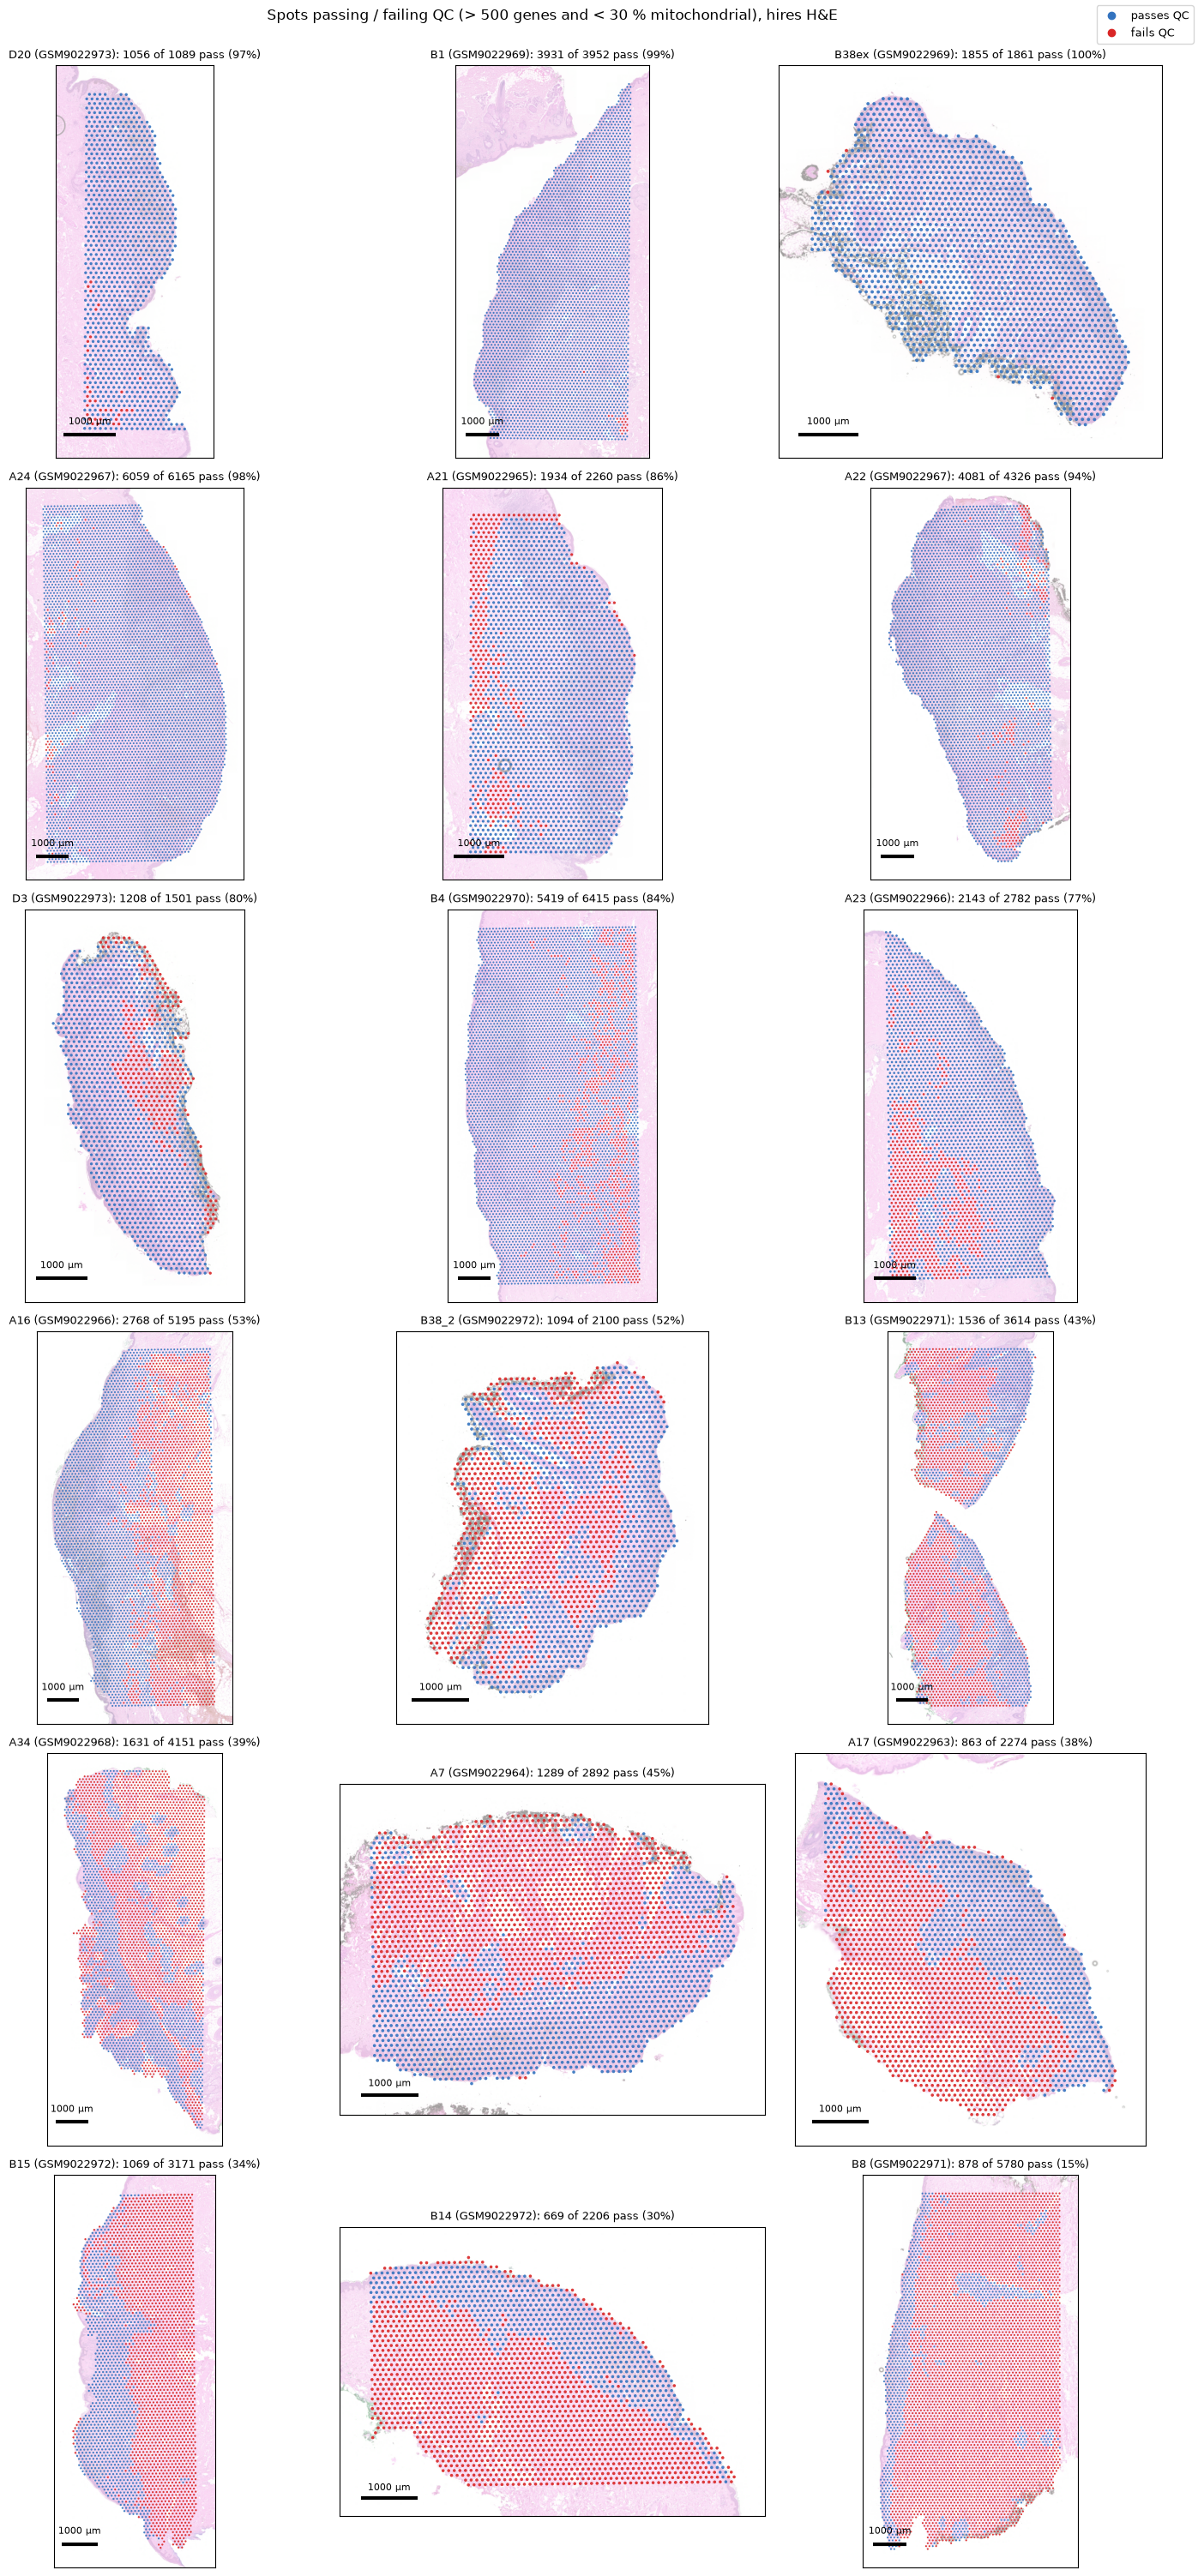

In [6]:
PASS_C, FAIL_C = np.array([0.20, 0.45, 0.75, 0.9]), np.array([0.85, 0.15, 0.15, 0.9])
fig, axes = splot.grid_axes(len(order), ncols=3, size=5.0)
for ax, s in zip(axes, order):
    g = next(gg for gg, ss in adatas if ss == s)
    a = adatas[(g, s)]
    img, x, y, um = sio.section_image(P, a, "hires")
    ok = a.obs.qc_pass.to_numpy()
    rgba = np.where(ok[:, None], PASS_C, FAIL_C)
    ax.imshow(img, alpha=0.4)                                   # faded H&E
    splot.spot_circles(ax, x, y, sio.SPOT_DIAMETER_UM / um, facecolors=rgba, alpha=None)
    splot.crop_to(ax, x, y, 10 * sio.SPOT_DIAMETER_UM / um)
    splot.scalebar(ax, 1000, um)
    ax.set_title(f"{s} ({g}): {ok.sum()} of {len(ok)} pass ({ok.mean():.0%})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=PASS_C[:3], label="passes QC"),
           plt.Line2D([], [], marker="o", ls="", color=FAIL_C[:3], label="fails QC")]
fig.legend(handles=handles, loc="upper right", fontsize=9)
fig.suptitle("Spots passing / failing QC (> 500 genes and < 30 % mitochondrial), hires H&E", y=1.0)
fig.tight_layout()
splot.savefig(fig, FIG / "qc_spatial_all_sections.png")
plt.show()

## 2.6 · Spot totals compared with the paper

The paper reports 39,481 spots in its final data (Results p. 4403: "atlas contained 39,481 spots"; Methods, deconvolution: "18,072 features and 39,481 spots") for its 18 analysed sections.
That set includes A2 (not usable here) and excludes B38ex (Supplementary Fig. S1C). The totals below are therefore
**not expected to be equal**; they are printed only to document the difference.

In [7]:
tot = qc_summary.assign(group=np.where(qc_summary.in_paper_S1C, "paper-analysed sections available here",
                                       "not in paper set (B38ex)"))
tot.groupby("group")[["n_spots", "n_pass"]].sum().assign(paper_reported_after_filter=39481)

,n_spots,n_pass,paper_reported_after_filter
group,,,
not in paper set (B38ex),1861,1855,39481
paper-analysed sections available here,59873,37628,39481


## 2.7 · Write QC flags into the spot manifest

Adds `total_counts, n_genes, pct_mt, qc_genes_ok, qc_mt_ok, qc_pass` to `manifests/spots.csv.gz`
(joined on `spot_uid`; re-running replaces the columns).

In [8]:
qc_cols = ["total_counts", "n_genes", "pct_mt", "qc_genes_ok", "qc_mt_ok", "qc_pass"]
qc = pd.concat([a.obs[["spot_uid"] + qc_cols] for a in adatas.values()], ignore_index=True)
spots = pd.read_csv(MAN / "spots.csv.gz")
spots = spots.drop(columns=[c for c in qc_cols if c in spots.columns]).merge(qc, on="spot_uid", how="left")
spots.to_csv(MAN / "spots.csv.gz", index=False, compression="gzip")
print(spots.shape, "| spots without QC values:", int(spots.qc_pass.isna().sum()))

(61734, 20) | spots without QC values: 0


## 2.8 · Observations

*From the outputs of this run (8 Nov 2026).*

* **Gene panels (2.2).** The 18,085-feature panel (A16, A21, A23) contains 11 `MT-` genes; the 37,082-feature panel
  (other 15 sections) contains 13.
* **Which rule removes spots (2.3).** The mitochondrial rule removes almost nothing: 100 % of spots pass it in every
  section except B8 (99.9 %); median mitochondrial % per section is 2.4–5.9. Failures are therefore due to the > 500 genes rule. Two spots have zero counts (one in A22, one in A7).
* **Pass rates (2.3).** From 15.2 % (B8) to 99.7 % (B38ex). Seven sections keep fewer than half of their spots:
  B13 (42.5 %), A7 (44.6 %), A34 (39.3 %), A17 (38.0 %), B15 (33.7 %), B14 (30.3 %), B8 (15.2 %); these are the
  seven sections whose median number of detected genes is below 500 (70–402).
  The highest-depth sections are D20, B1, B38ex and A24 (median 11,291–21,899 UMIs per spot, ≥ 97 % pass).
* **Distributions (2.4).** Several sections show two peaks in counts and detected genes (visible in the violins).
* **Where failing spots are (2.5).** Failing spots are mostly not scattered: in most sections they form contiguous
  areas next to contiguous areas of passing spots. Examples: the lower half of A17, the lower part of B14, most of
  B8 except a strip on the left, the right part of A16 and of B15, a strip on the left of A21, the right side of B4,
  a central area of D3, and the upper part of A7. In some sections failing spots also line the tissue edge
  (e.g. D3, B38_2, A22). In the highest-pass sections (D20, B1, B38ex, A24) only isolated spots fail.
  Consequence for later notebooks: in the low-pass sections, the QC-passing spots do not cover whole tissue
  areas, so analyses restricted to `qc_pass` spots leave those areas out.
* **Totals vs the paper (2.6).** After QC: 39,483 spots in the 18 usable sections (37,628 in the sections that appear
  in Supp. Fig. S1C, plus 1,855 in B38ex). The paper reports 39,481. The near-equal total is obtained with B38ex
  included and A2 absent, whereas Supp. Fig. S1C lists A2 and not B38ex; which sections the paper's 39,481 refers to
  cannot be determined from the public data.
* **Manifest (2.7).** QC values were added for all 61,734 spots in `spots.csv.gz` (0 spots without QC values).